# 01 · Data understanding and preprocessing

## Setup

In [1]:
# --- setup: works on Mac, Colab and Kaggle; safe to re-run after a crash ---
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-object-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwdet import env
from hwdet.data.download import ensure_data
P = env.setup(seed=42)
ensure_data(P, labels_only=True)

platform: local
    data: /Users/anna/Desktop/AI/ucu-ai-hw-object-detection/data
 outputs: /Users/anna/Desktop/AI/ucu-ai-hw-object-detection/outputs
   cache: /Users/anna/Desktop/AI/ucu-ai-hw-object-detection/outputs/cache
    repo: /Users/anna/Desktop/AI/ucu-ai-hw-object-detection
  device: cpu
data ready at /Users/anna/Desktop/AI/ucu-ai-hw-object-detection/data


PosixPath('/Users/anna/Desktop/AI/ucu-ai-hw-object-detection/data')

In [2]:
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter
from hwdet import CLASS_NAMES
from hwdet.data.io import frame_table, annotations_table, load_coco
from hwdet.viz import BLUES, COLORS, INK, INK_2, INK_3, SPLIT_COLORS, save_fig, set_style

set_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
SPLITS = ["train", "val"]
CLS = dict(enumerate(CLASS_NAMES))


def short(clip):
    """'uav0000013_00000_v' -> '013_00000'"""
    return clip[7:-2]


F = {s: frame_table(P.data, s) for s in SPLITS + ["test"]}
A = {s: annotations_table(P.data, s) for s in SPLITS}
load_coco.cache_clear(); gc.collect()       # the raw json takes ~2 GB in memory; the tables are enough

# objects vs ignored regions; every ignored region is stored once per class (8 copies) -> deduplicate
OBJ = {s: a[a.iscrowd == 0].reset_index(drop=True) for s, a in A.items()}
IGN = {s: a[a.iscrowd == 1].drop_duplicates(["coco_id", "x", "y", "w", "h"]).reset_index(drop=True)
       for s, a in A.items()}
split_of = pd.concat(F.values()).drop_duplicates("clip").set_index("clip")["split"]
OBJ["train"].head()

,coco_id,iscrowd,truncation,occlusion,track_id,orig_category_id,ignore,x,y,w,h,cls,clip,frame,img_w,img_h,area,size
0,1,0,0.0,0.0,2.0,1,NaN,424.0,543.0,35.0,88.0,0,uav0000013_00000_v,1,1344,756,3080.0,medium
1,1,0,0.0,1.0,3.0,1,NaN,416.0,530.0,36.0,85.0,0,uav0000013_00000_v,1,1344,756,3060.0,medium
2,1,0,1.0,0.0,4.0,7,NaN,531.0,641.0,87.0,114.0,5,uav0000013_00000_v,1,1344,756,9918.0,large
3,1,0,0.0,0.0,5.0,1,NaN,591.0,422.0,32.0,79.0,0,uav0000013_00000_v,1,1344,756,2528.0,medium
4,1,0,0.0,0.0,6.0,1,NaN,454.0,413.0,21.0,48.0,0,uav0000013_00000_v,1,1344,756,1008.0,small


## 1. Overview
Size of each split and the image resolutions in it. Sizes that differ by 1–2 px are merged.

In [3]:
overview = pd.DataFrame({
    s: {"clips": F[s]["clip"].nunique(), "frames": len(F[s]),
        "frames per clip (median)": int(F[s].groupby("clip").size().median()),
        "objects": len(OBJ[s]) if s in OBJ else pd.NA,
        "ignored regions": len(IGN[s]) if s in IGN else pd.NA}
    for s in SPLITS + ["test"]}).T.astype("Int64")
overview

,clips,frames,frames per clip (median),objects,ignored regions
train,56,24201,383,1105516,63843
val,7,2846,349,114132,3995
test,48,3811,73,<NA>,<NA>


split,train,val,test
res,,,
1344×756,11,2,7
1360×764,1,0,18
1904×1071,30,2,4
1920×1080,1,0,11
2688×1512,11,1,0
2720×1530,2,1,0
3840×2160,0,1,0
680×382,0,0,3
960×540,0,0,5


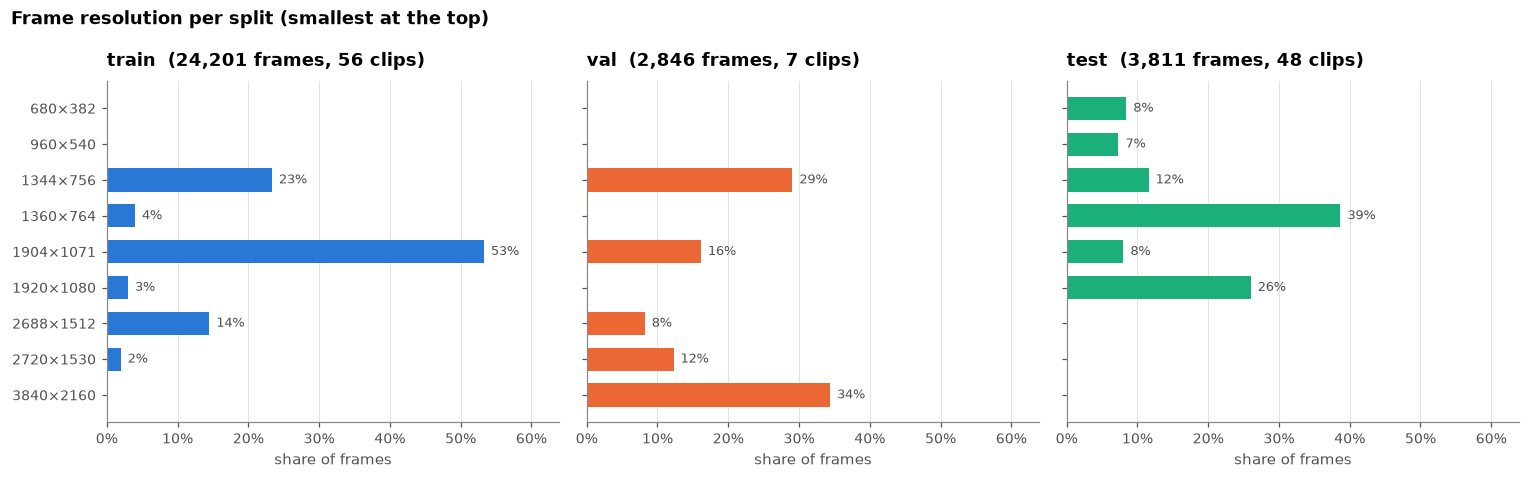

In [4]:
res = pd.concat(F.values(), ignore_index=True)
# sizes that differ by 1-2 px (1360×764 / 1360×765, 1904×1071 / 1904×1072) are the same camera mode
merged = {}
for w, h in sorted(set(zip(res.width, res.height))):
    same = [k for k in merged.values() if k[0] == w and abs(k[1] - h) <= 2]
    merged[(w, h)] = same[0] if same else (w, h)
res["res"] = [f"{merged[(w, h)][0]}×{merged[(w, h)][1]}" for w, h in zip(res.width, res.height)]
res["pixels"] = [merged[(w, h)][0] * merged[(w, h)][1] for w, h in zip(res.width, res.height)]
order = res.drop_duplicates("res").sort_values("pixels").res.tolist()
share = pd.crosstab(res.res, res.split, normalize="columns").reindex(order)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True, sharex=True)
for ax, s in zip(axes, ["train", "val", "test"]):
    v = share[s]
    ax.barh(order, v, color=SPLIT_COLORS[s], height=0.65)
    for r, x in v.items():
        if x > 0:
            ax.text(x + 0.01, r, f"{x:.0%}", va="center", fontsize=8.5, color=INK_2)
    ax.set_title(f"{s}  ({len(F[s]):,} frames, {F[s]['clip'].nunique()} clips)")
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("share of frames")
    ax.grid(axis="y", visible=False)
axes[0].invert_yaxis()
axes[0].set_xlim(0, share.max().max() * 1.2)
fig.suptitle("Frame resolution per split (smallest at the top)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "eda_resolutions", P)
pd.crosstab(res.drop_duplicates("clip").res, res.drop_duplicates("clip").split)[["train", "val", "test"]]

## 2. Class distribution
The 8 competition classes merge some of VisDrone's original 10 classes:
pedestrian + people → person, tricycle + awning-tricycle → tricycle.
Counts are labelled objects; ignored regions are excluded.

In [5]:
VISDRONE = {1: "pedestrian", 2: "people", 3: "bicycle", 4: "car", 5: "van", 6: "truck",
            7: "tricycle", 8: "awning-tricycle", 9: "bus", 10: "motor"}
m = OBJ["train"].groupby(["cls", "orig_category_id"]).size().reset_index(name="objects")
m["class"] = m.cls.map(CLS)
m["VisDrone class"] = m.orig_category_id.map(VISDRONE)
m[["class", "VisDrone class", "objects"]]

,class,VisDrone class,objects
0,person,pedestrian,234305
1,person,people,94396
2,bicycle,bicycle,40255
3,car,car,505301
4,van,van,46940
5,truck,truck,30498
6,tricycle,tricycle,28338
7,tricycle,awning-tricycle,13011
8,bus,bus,9653
9,motor,motor,102819


,train %,val %,train objects,val objects
cls,,,,
person,29.7,44.1,328701,50312
bicycle,3.6,5.3,40255,6022
car,45.7,27.9,505301,31821
van,4.2,6.0,46940,6842
truck,2.8,1.2,30498,1359
tricycle,3.7,4.8,41349,5487
bus,0.9,0.2,9653,264
motor,9.3,10.5,102819,12025


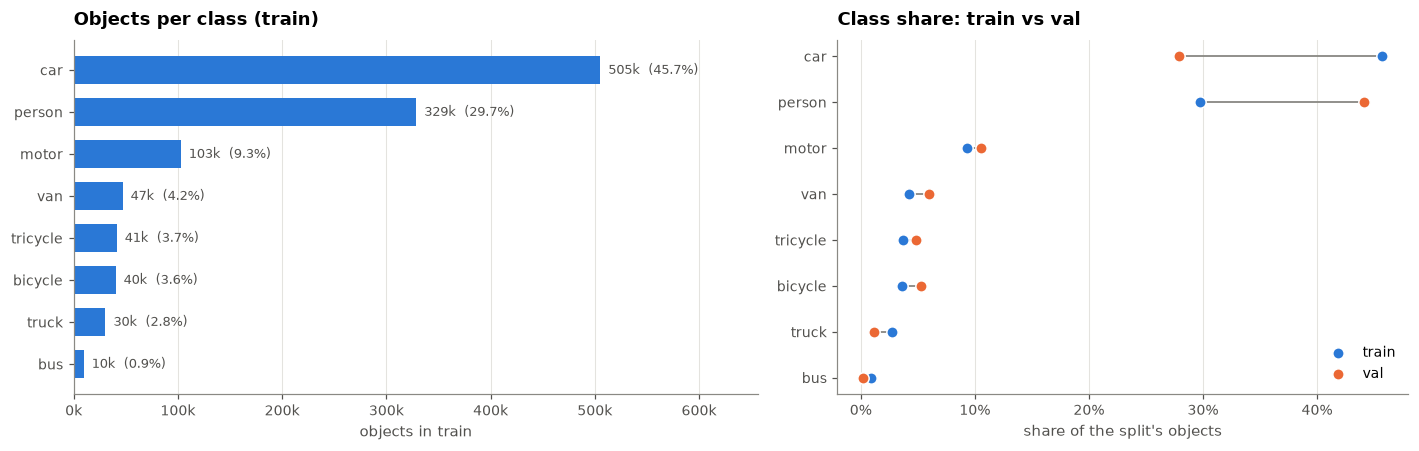

In [6]:
counts = pd.DataFrame({s: OBJ[s].cls.value_counts() for s in SPLITS}).rename(index=CLS)
share = counts / counts.sum()
order = counts.train.sort_values().index          # largest class at the top

fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
a0.barh(order, counts.train[order], color=SPLIT_COLORS["train"], height=0.65)
for c in order:
    a0.text(counts.train[c], c, f"  {counts.train[c] / 1e3:,.0f}k  ({share.train[c]:.1%})",
            va="center", fontsize=8.5, color=INK_2)
a0.set_xlim(0, counts.train.max() * 1.3)
a0.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e3:.0f}k"))
a0.set_xlabel("objects in train")
a0.set_title("Objects per class (train)")
a0.grid(axis="y", visible=False)

for c in order:
    a1.plot([share.train[c], share.val[c]], [c, c], color=INK_3, lw=1.2, zorder=1)
for s in SPLITS:
    a1.scatter(share[s][order], order, s=55, color=SPLIT_COLORS[s], label=s, zorder=2,
               edgecolor="white", linewidth=1)
a1.xaxis.set_major_formatter(PercentFormatter(1))
a1.set_xlabel("share of the split's objects")
a1.set_title("Class share: train vs val")
a1.legend(loc="lower right")
a1.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "eda_class_distribution", P)
(share * 100).round(1).add_suffix(" %").join(counts.add_suffix(" objects"))

Class mix per clip: one column per clip, colour = share of that clip's objects.

PosixPath('/Users/anna/Desktop/AI/ucu-ai-hw-object-detection/outputs/figures/eda_class_per_clip.png')

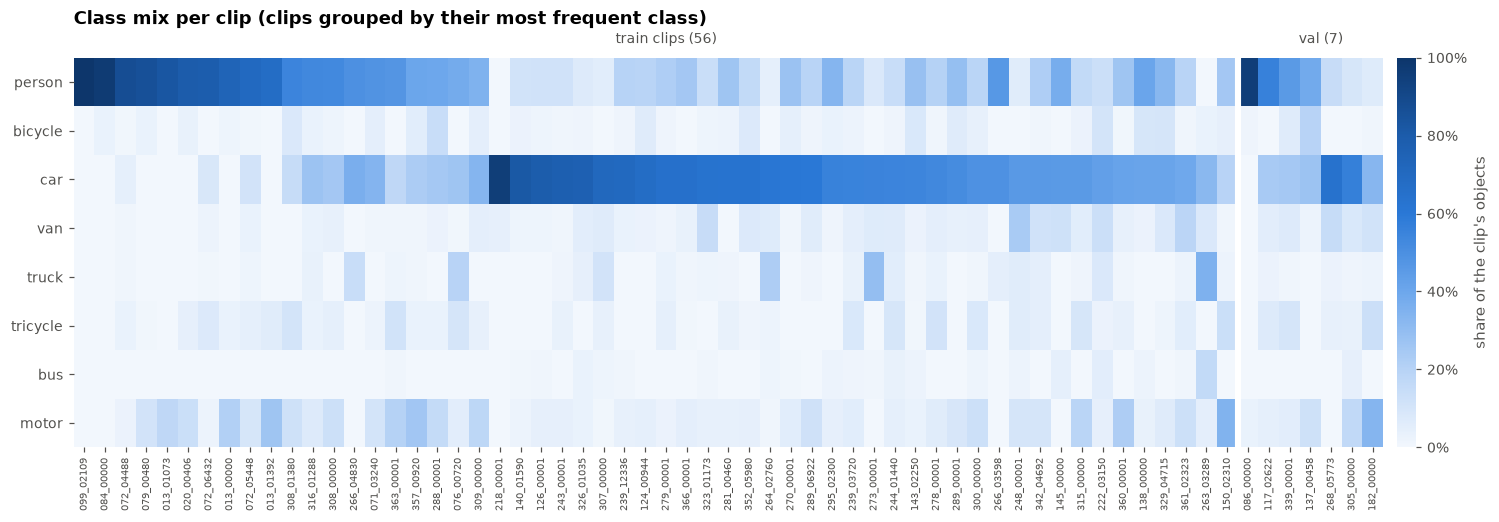

In [7]:
both = pd.concat(OBJ.values())
mix = pd.crosstab(both["clip"], both.cls, normalize="index").reindex(columns=range(len(CLASS_NAMES)), fill_value=0)
mix.columns = CLASS_NAMES
mix["split"] = split_of.reindex(mix.index)
mix["dominant"] = mix[CLASS_NAMES].values.argmax(1)
mix["top_share"] = mix[CLASS_NAMES].max(axis=1)
mix = mix.sort_values(["split", "dominant", "top_share"], ascending=[True, True, False])
n_train = (mix.split == "train").sum()

fig, ax = plt.subplots(figsize=(16, 4.6))
im = ax.imshow(mix[CLASS_NAMES].T.values, aspect="auto", cmap=BLUES, vmin=0, vmax=1)
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
ax.set_xticks(range(len(mix)), [short(c) for c in mix.index], rotation=90, fontsize=6.5)
ax.axvline(n_train - 0.5, color="white", lw=4)
ax.text(n_train / 2, -0.8, f"train clips ({n_train})", ha="center", fontsize=9, color=INK_2)
ax.text(n_train + (len(mix) - n_train) / 2, -0.8, f"val ({len(mix) - n_train})", ha="center",
        fontsize=9, color=INK_2)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.01, fraction=0.03, format=PercentFormatter(1))
cb.set_label("share of the clip's objects")
cb.outline.set_visible(False)
ax.set_title("Class mix per clip (clips grouped by their most frequent class)", pad=22)
save_fig(fig, "eda_class_per_clip", P)

## 3. Object sizes
Object size = √(w·h) of the box in original pixels. COCO buckets: small < 32 px, medium 32–96 px, large > 96 px.

In [8]:
for s in SPLITS:
    o = OBJ[s]
    o["side"] = np.sqrt(o.area)                                   # sqrt(area) in pixels
    o["rel_side"] = o.side / np.sqrt(o.img_w * o.img_h)          # relative to the image size
    o["aspect"] = o.h / o.w.clip(lower=1)

o = OBJ["train"]
(pd.DataFrame({s: OBJ[s]["size"].value_counts(normalize=True) for s in SPLITS})
   .loc[["small", "medium", "large"]] * 100).round(1).add_suffix(" %")

,train %,val %
size,,
small,24.9,19.2
medium,63.5,69.5
large,11.6,11.3


PosixPath('/Users/anna/Desktop/AI/ucu-ai-hw-object-detection/outputs/figures/eda_object_sizes.png')

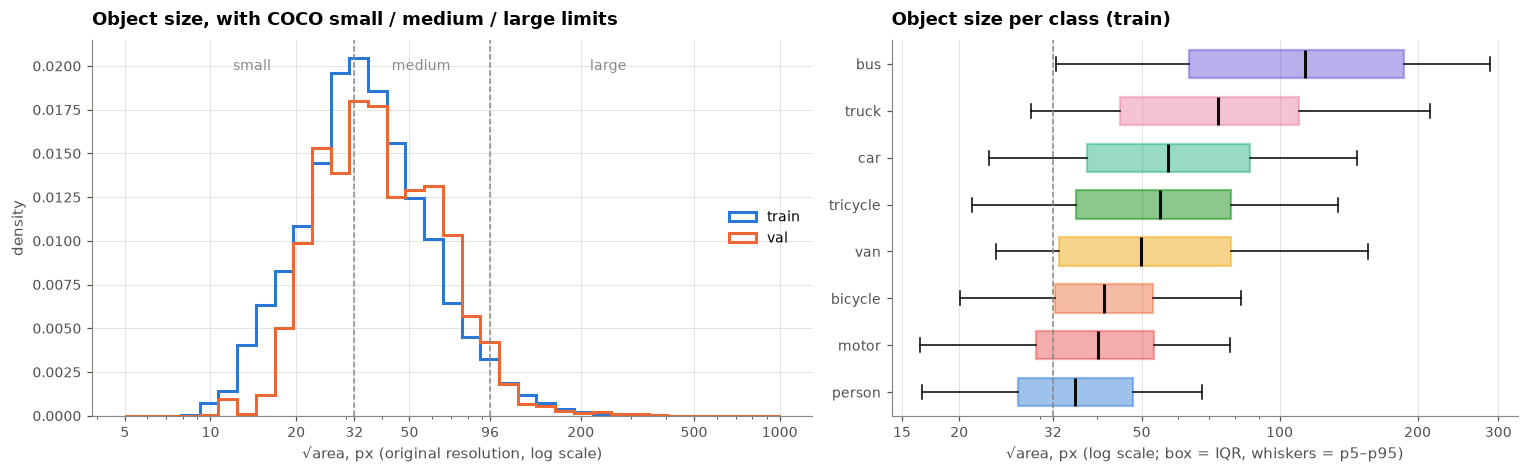

In [9]:
size_order = o.groupby("cls").side.median().sort_values().index      # smallest class at the bottom

fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
bins = np.logspace(np.log10(5), np.log10(1000), 36)
for s in SPLITS:
    a0.hist(OBJ[s].side, bins=bins, density=True, histtype="step", lw=2, color=SPLIT_COLORS[s], label=s)
a0.set_xscale("log")
for t in (32, 96):
    a0.axvline(t, color=INK_3, ls="--", lw=1)
ymax = a0.get_ylim()[1]
for x, lab in ((14, "small"), (55, "medium"), (250, "large")):
    a0.text(x, ymax * 0.95, lab, ha="center", va="top", fontsize=9, color=INK_3)
a0.set_xticks([5, 10, 20, 32, 50, 96, 200, 500, 1000], ["5", "10", "20", "32", "50", "96", "200", "500", "1000"])
a0.xaxis.set_minor_formatter(NullFormatter())
a0.set_xlabel("√area, px (original resolution, log scale)")
a0.set_ylabel("density")
a0.set_title("Object size, with COCO small / medium / large limits")
a0.legend(loc="center right")

parts = a1.boxplot([o.side[o.cls == c] for c in size_order], orientation="horizontal", whis=(5, 95), showfliers=False,
                   patch_artist=True, widths=0.6, medianprops={"color": INK, "lw": 2})
for patch, c in zip(parts["boxes"], size_order):
    patch.set(facecolor=COLORS[c], alpha=0.45, edgecolor=COLORS[c], linewidth=1.5)
a1.set_yticks(range(1, len(size_order) + 1), [CLS[c] for c in size_order])
a1.set_xscale("log")
a1.axvline(32, color=INK_3, ls="--", lw=1)
a1.set_xticks([15, 20, 32, 50, 100, 200, 300], ["15", "20", "32", "50", "100", "200", "300"])
a1.xaxis.set_minor_formatter(NullFormatter())
a1.set_xlabel("√area, px (log scale; box = IQR, whiskers = p5–p95)")
a1.set_title("Object size per class (train)")
a1.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "eda_object_sizes", P)

In [10]:
# size depends on the clip's resolution and flight altitude
by_res = o.assign(res=o.img_w.astype(str) + "×" + o.img_h.astype(str)).groupby("res").agg(
    clips=("clip", "nunique"), objects=("side", "size"), median_side_px=("side", "median"),
    median_relative_side=("rel_side", "median"))
by_res.sort_values("median_side_px").round(3)

,clips,objects,median_side_px,median_relative_side
res,,,,
1360×765,1,52919,31.496,0.031
1344×756,11,155031,32.985,0.033
1920×1080,1,40928,38.210,0.027
1904×1071,30,593183,47.739,0.033
2688×1512,11,230795,54.222,0.027
2720×1530,2,32660,58.095,0.028


In [11]:
# Test clips have other resolutions than train (section 1). The relative object size is similar across
# resolutions, so estimate the object size in test pixels as median relative side × test image size.
rel = o.rel_side.median()
t = F["test"].assign(res=F["test"].width.astype(str) + "×" + F["test"].height.astype(str))
t = t.groupby("res").agg(clips=("clip", "nunique"), frames=("frame", "size"),
                         w=("width", "first"), h=("height", "first"))
t["expected median side px"] = (rel * np.sqrt(t.w * t.h)).round(1)
t.sort_values("w").drop(columns=["w", "h"])

,clips,frames,expected median side px
res,,,
680×382,3,321,16.1
960×540,5,279,22.8
1344×756,7,441,31.9
1360×764,18,1474,32.3
1904×1072,4,305,45.2
1920×1080,11,991,45.6


Share of objects below 8 / 16 / 32 px when the long image side is resized to N px, and box aspect ratios.

,median side px,< 8 px,< 16 px,< 32 px
640,15.196,0.098,0.542,0.890
960,22.794,0.017,0.240,0.735
1280,30.392,0.006,0.098,0.542
1600,37.990,0.002,0.038,0.370
1920,45.588,0.000,0.017,0.240


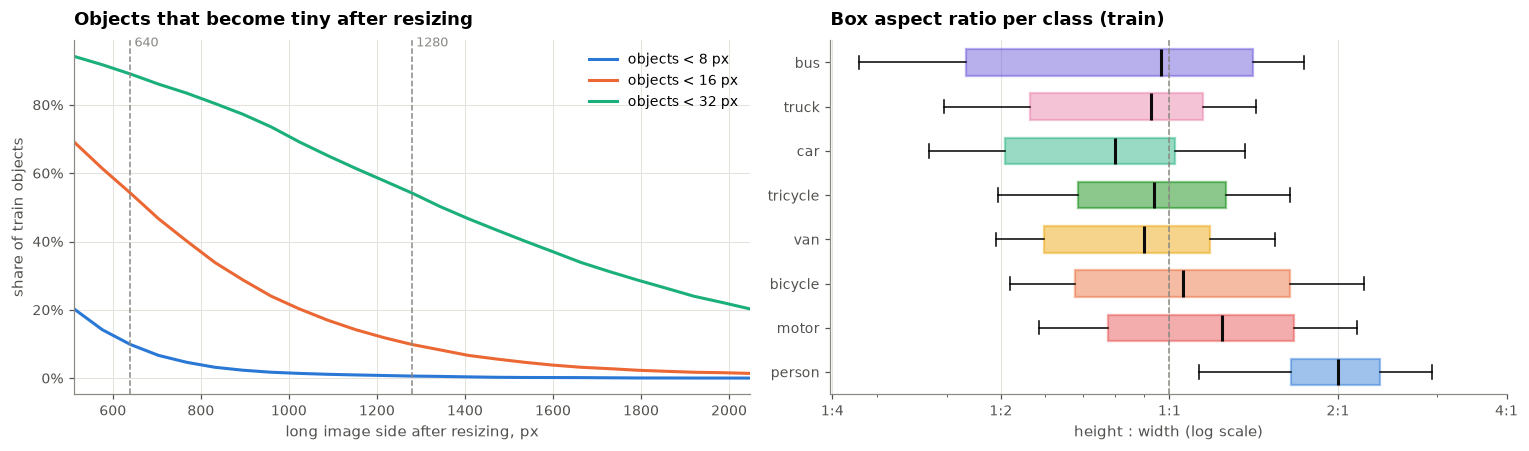

In [12]:
# If the long image side is resized to N px, how many objects become tiny?
Ns = np.arange(512, 2049, 64)
scale = Ns[:, None] / np.maximum(o.img_w, o.img_h).to_numpy()[None]
scaled = o.side.to_numpy()[None] * scale
tiny = {f"< {k} px": (scaled < k).mean(1) for k in (8, 16, 32)}

size_order = o.groupby("cls").side.median().sort_values().index
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
for (lab, v), col in zip(tiny.items(), COLORS):
    a0.plot(Ns, v, color=col, label=f"objects {lab}")
for n in (640, 1280):
    a0.axvline(n, color=INK_3, ls="--", lw=1)
    a0.text(n, 1.0, f" {n}", va="top", fontsize=8.5, color=INK_3)
a0.set_xlim(Ns[0], Ns[-1])
a0.yaxis.set_major_formatter(PercentFormatter(1))
a0.set_xlabel("long image side after resizing, px")
a0.set_ylabel("share of train objects")
a0.set_title("Objects that become tiny after resizing")
a0.legend(loc="upper right")

parts = a1.boxplot([o.aspect[o.cls == c] for c in size_order], orientation="horizontal", whis=(5, 95), showfliers=False,
                   patch_artist=True, widths=0.6, medianprops={"color": INK, "lw": 2})
for patch, c in zip(parts["boxes"], size_order):
    patch.set(facecolor=COLORS[c], alpha=0.45, edgecolor=COLORS[c], linewidth=1.5)
a1.set_yticks(range(1, len(size_order) + 1), [CLS[c] for c in size_order])
a1.set_xscale("log")
a1.set_xticks([0.25, 0.5, 1, 2, 4], ["1:4", "1:2", "1:1", "2:1", "4:1"])
a1.xaxis.set_minor_formatter(NullFormatter())
a1.axvline(1, color=INK_3, ls="--", lw=1)
a1.set_xlabel("height : width (log scale)")
a1.set_title("Box aspect ratio per class (train)")
a1.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "eda_resize_and_aspect", P)
pd.DataFrame({N: {"median side px": np.median(scaled[i]), **{k: v[i] for k, v in tiny.items()}}
              for i, N in enumerate(Ns) if N in (640, 960, 1280, 1600, 1920)}).T.round(3)

## 4. Objects per frame (scene density)
Labelled objects per frame, ignored regions excluded.

In [13]:
dens = {}
for s in SPLITS:
    n = OBJ[s].groupby("coco_id").size()
    dens[s] = F[s].set_index("coco_id").assign(n_obj=n).fillna({"n_obj": 0})
pd.DataFrame({s: {**d.n_obj.quantile([.5, .9, .99]).rename(lambda v: f"p{int(v * 100)}").to_dict(),
                  "max": d.n_obj.max(), "> 100 objects": f"{(d.n_obj > 100).mean():.1%}"}
              for s, d in dens.items()}).T

,p50,p90,p99,max,> 100 objects
train,43.0,92.0,142.0,180.0,7.6%
val,37.0,81.0,112.55,116,6.4%


PosixPath('/Users/anna/Desktop/AI/ucu-ai-hw-object-detection/outputs/figures/eda_density_per_clip.png')

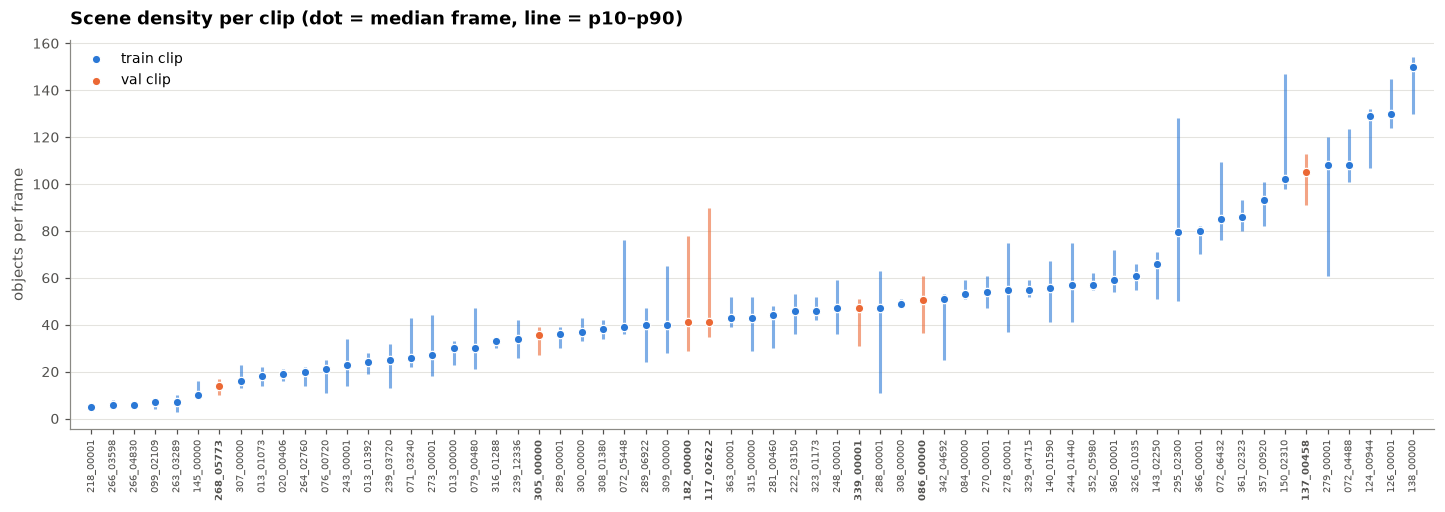

In [14]:
both = pd.concat(dens.values())
stats = both.groupby("clip").n_obj.quantile([0.1, 0.5, 0.9]).unstack()
stats.columns = ["p10", "median", "p90"]
stats["split"] = split_of.reindex(stats.index)
stats = stats.sort_values("median")
x = np.arange(len(stats))

fig, ax = plt.subplots(figsize=(16, 4.6))
for s in SPLITS:
    m = (stats.split == s).to_numpy()
    ax.vlines(x[m], stats.p10[m], stats.p90[m], color=SPLIT_COLORS[s], lw=2, alpha=0.6)
    ax.scatter(x[m], stats["median"][m], s=30, color=SPLIT_COLORS[s], zorder=3, edgecolor="white",
               linewidth=0.8, label=f"{s} clip")
ax.set_xticks(x, [short(c) for c in stats.index], rotation=90, fontsize=6.5)
for lab, s in zip(ax.get_xticklabels(), stats.split):
    if s == "val":
        lab.set_fontweight("bold")
ax.set_xlim(-1, len(x))
ax.set_ylabel("objects per frame")
ax.set_title("Scene density per clip (dot = median frame, line = p10–p90)")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
save_fig(fig, "eda_density_per_clip", P)

## 5. Variation across sequences
Per-clip statistics, and the official val clips compared with train clips.

In [15]:
def clip_table(s):
    o, f = OBJ[s], dens[s]
    t = f.groupby("clip").agg(width=("width", "first"), height=("height", "first"),
                              frames=("frame", "size"), obj_per_frame=("n_obj", "mean"))
    t["res"] = t.width.astype(str) + "×" + t.height.astype(str)
    g = o.groupby("clip")
    t["median_side"] = g.side.median()
    t["small_share"] = g["size"].apply(lambda x: (x == "small").mean())
    t["top_class"] = g.cls.agg(lambda c: CLS[c.mode()[0]])
    t["n_classes"] = g.cls.nunique()
    t["split"] = s
    return t.drop(columns=["width", "height"])

clips = pd.concat([clip_table(s) for s in SPLITS]).round(3)
clips.sort_values("obj_per_frame")

,frames,obj_per_frame,res,median_side,small_share,top_class,n_classes,split
clip,,,,,,,,
uav0000218_00001_v,225,5.147,2688×1512,62.141,0.018,car,3,train
uav0000266_04830_v,116,6.086,2688×1512,81.584,0.000,person,3,train
uav0000263_03289_v,725,6.463,1904×1071,54.854,0.118,truck,6,train
uav0000266_03598_v,548,6.474,2688×1512,80.923,0.000,car,3,train
uav0000099_02109_v,1255,7.135,1344×756,37.081,0.287,person,1,train
...,...,...,...,...,...,...,...,...
uav0000150_02310_v,348,108.885,2688×1512,60.033,0.051,motor,7,train
uav0000072_04488_v,85,110.376,1904×1071,45.826,0.147,person,7,train
uav0000124_00944_v,398,124.568,2688×1512,46.314,0.242,car,6,train


## 6. Ignored regions
Crowds, dense parking and VisDrone's "others". The scoring does not penalise detections inside them.

In [16]:
def centers_in_ignore(obj, ign):
    """Share of labelled objects whose centre lies inside an ignored region of the same frame."""
    ign_by = {k: g[["x", "y", "w", "h"]].to_numpy() for k, g in ign.groupby("coco_id")}
    hits, total = 0, 0
    for k, g in obj.groupby("coco_id"):
        total += len(g)
        r = ign_by.get(k)
        if r is None:
            continue
        cx = (g.x + g.w / 2).to_numpy()[:, None]
        cy = (g.y + g.h / 2).to_numpy()[:, None]
        inside = (cx >= r[:, 0]) & (cx <= r[:, 0] + r[:, 2]) & (cy >= r[:, 1]) & (cy <= r[:, 1] + r[:, 3])
        hits += inside.any(axis=1).sum()
    return hits / total

rows = {}
for s in SPLITS:
    ig = IGN[s]
    per_frame = ig.groupby("coco_id").size().reindex(F[s].coco_id, fill_value=0)
    cover = (ig.area / (ig.img_w * ig.img_h)).groupby(ig.coco_id).sum().reindex(F[s].coco_id, fill_value=0)
    rows[s] = {"frames with ignored regions": f"{(per_frame > 0).mean():.1%}",
               "regions per frame (median / max)": f"{per_frame.median():.0f} / {per_frame.max()}",
               "image area covered (mean / p95)": f"{cover.mean():.1%} / {cover.quantile(.95):.1%}",
               "objects with centre inside a region": f"{centers_in_ignore(OBJ[s], ig):.2%}",
               "'others' regions (VisDrone id 11)": int((ig.orig_category_id == 11).sum())}
pd.DataFrame(rows)

,train,val
frames with ignored regions,74.7%,50.4%
regions per frame (median / max),2 / 22,1 / 7
image area covered (mean / p95),2.4% / 10.2%,1.6% / 8.6%
objects with centre inside a region,1.14%,1.08%
'others' regions (VisDrone id 11),1474,1


## 7. Temporal redundancy → frame subsampling
Consecutive frames are almost identical. How much does a box move after k frames, and how many
distinct objects (tracks) are still seen when only every k-th frame is kept?

tracks: 7342, track length (frames): median 103, p10 21


,median IoU,IoU > 0.7,frames kept,tracks still seen
frame step k,,,,
1,0.897,0.862,1.000,1.000
2,0.810,0.671,0.501,0.996
3,0.731,0.541,0.334,0.997
5,0.597,0.397,0.201,0.993
10,0.357,0.259,0.101,0.986
20,0.102,0.180,0.051,0.967
50,0.000,0.122,0.021,0.914


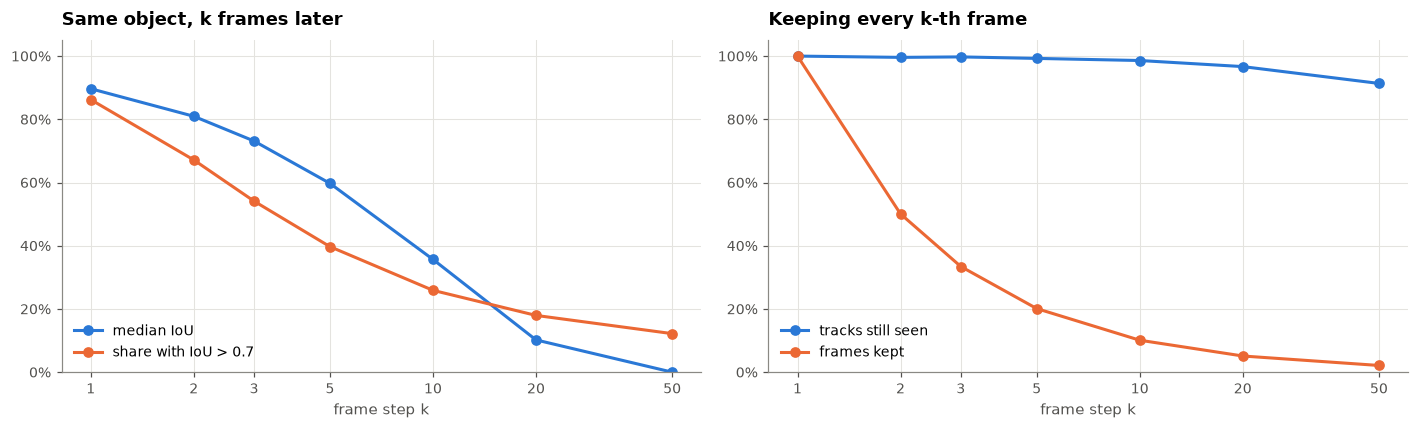

In [17]:
o = OBJ["train"][["clip", "frame", "track_id", "x", "y", "w", "h"]].dropna(subset=["track_id"])

def iou_after(k):
    nxt = o.assign(frame=o.frame - k)
    m = o.merge(nxt, on=["clip", "track_id", "frame"], suffixes=("", "_n"))
    x0 = np.maximum(m.x, m.x_n); y0 = np.maximum(m.y, m.y_n)
    x1 = np.minimum(m.x + m.w, m.x_n + m.w_n); y1 = np.minimum(m.y + m.h, m.y_n + m.h_n)
    inter = (x1 - x0).clip(lower=0) * (y1 - y0).clip(lower=0)
    return inter / (m.w * m.h + m.w_n * m.h_n - inter)

tracks = o.groupby(["clip", "track_id"]).size()
print(f"tracks: {len(tracks)}, track length (frames): median {tracks.median():.0f}, p10 {tracks.quantile(.1):.0f}")

ks = [1, 2, 3, 5, 10, 20, 50]
rows = {}
for k in ks:
    iou = iou_after(k)
    keep = o[(o.frame - 1) % k == 0]
    rows[k] = {"median IoU": iou.median(), "IoU > 0.7": (iou > 0.7).mean(),
               "frames kept": ((F["train"].frame - 1) % k == 0).mean(),
               "tracks still seen": keep.groupby(["clip", "track_id"]).ngroups / len(tracks)}
temporal = pd.DataFrame(rows).T
temporal.index.name = "frame step k"

fig, (a0, a1) = plt.subplots(1, 2, figsize=(13, 4))
a0.plot(ks, temporal["median IoU"], marker="o", color=COLORS[0], label="median IoU")
a0.plot(ks, temporal["IoU > 0.7"], marker="o", color=COLORS[1], label="share with IoU > 0.7")
a0.set_title("Same object, k frames later")
a1.plot(ks, temporal["tracks still seen"], marker="o", color=COLORS[0], label="tracks still seen")
a1.plot(ks, temporal["frames kept"], marker="o", color=COLORS[1], label="frames kept")
a1.set_title("Keeping every k-th frame")
for ax in (a0, a1):
    ax.set_xscale("log")
    ax.set_xticks(ks, [str(k) for k in ks])
    ax.minorticks_off()
    ax.set_xlabel("frame step k")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set_ylim(0, 1.05)
    ax.legend(loc="lower left")
fig.tight_layout()
save_fig(fig, "eda_temporal", P)
temporal.round(3)

## 8. Validation design
Frames from one clip are highly correlated, so splits are made **by clip**, never by frame.
GroupKFold puts every clip into exactly one fold; the assignment is saved to `results/splits/folds_gkf5.csv`.

In [18]:
from sklearn.model_selection import GroupKFold

labelled = pd.concat([F["train"], F["val"]], ignore_index=True)
labelled["fold"] = -1
for k, (_, idx) in enumerate(GroupKFold(n_splits=5).split(labelled, groups=labelled["clip"])):
    labelled.loc[idx, "fold"] = k
assert labelled.groupby("clip").fold.nunique().max() == 1      # no clip in two folds

labelled["n_obj"] = labelled.file_name.map(pd.concat(dens.values()).set_index("file_name").n_obj)
agg = dict(clips=("clip", "nunique"), frames=("file_name", "size"), obj_per_frame=("n_obj", "mean"))
folds = labelled.groupby("fold").agg(**agg)
folds.index = [f"fold {k}" for k in folds.index]
official = labelled[labelled.split == "val"].assign(g="official val").groupby("g").agg(**agg)
pd.concat([folds, official]).round(2)

,clips,frames,obj_per_frame
fold 0,12,5399,51.77
fold 1,13,5446,38.74
fold 2,12,5370,48.01
fold 3,13,5419,48.13
fold 4,13,5413,38.89
official val,7,2846,40.10


In [19]:
# clip -> fold assignment, so every machine (Colab / Kaggle) uses the same split
split_dir = P.repo / "results" / "splits"
split_dir.mkdir(parents=True, exist_ok=True)
labelled[["clip", "split", "fold"]].drop_duplicates().sort_values(["fold", "clip"]).to_csv(
    split_dir / "folds_gkf5.csv", index=False)
print("saved", split_dir / "folds_gkf5.csv")

saved /Users/anna/Desktop/AI/ucu-ai-hw-object-detection/results/splits/folds_gkf5.csv


## 9. Visual check of the annotations
A few frames are downloaded. The COCO boxes and ignored regions are drawn on them, and the YOLO label
files are checked to give the same boxes, which verifies the conversion between the two formats.

In [20]:
from PIL import Image
from hwdet.data.download import download_frames
from hwdet.data.io import load_gt

# middle frame of 4 clips spanning the density range
pick = clips.sort_values("obj_per_frame").iloc[np.linspace(0, len(clips) - 1, 4).astype(int)].index
sample = pd.concat([F[split_of[c]][F[split_of[c]]["clip"] == c].iloc[[len(F[split_of[c]][F[split_of[c]]["clip"] == c]) // 2]]
                    for c in pick])
download_frames(P, sample.file_name.tolist())
sample[["file_name", "width", "height"]]

,file_name,width,height
6326,train/images/uav0000218_00001_v/0000113.jpg,2688,1512
2067,train/images/uav0000079_00480_v/0000181.jpg,1904,1071
2506,train/images/uav0000084_00000_v/0000259.jpg,1344,756
4935,train/images/uav0000138_00000_v/0000107.jpg,2688,1512


COCO and YOLO labels agree on all sampled frames


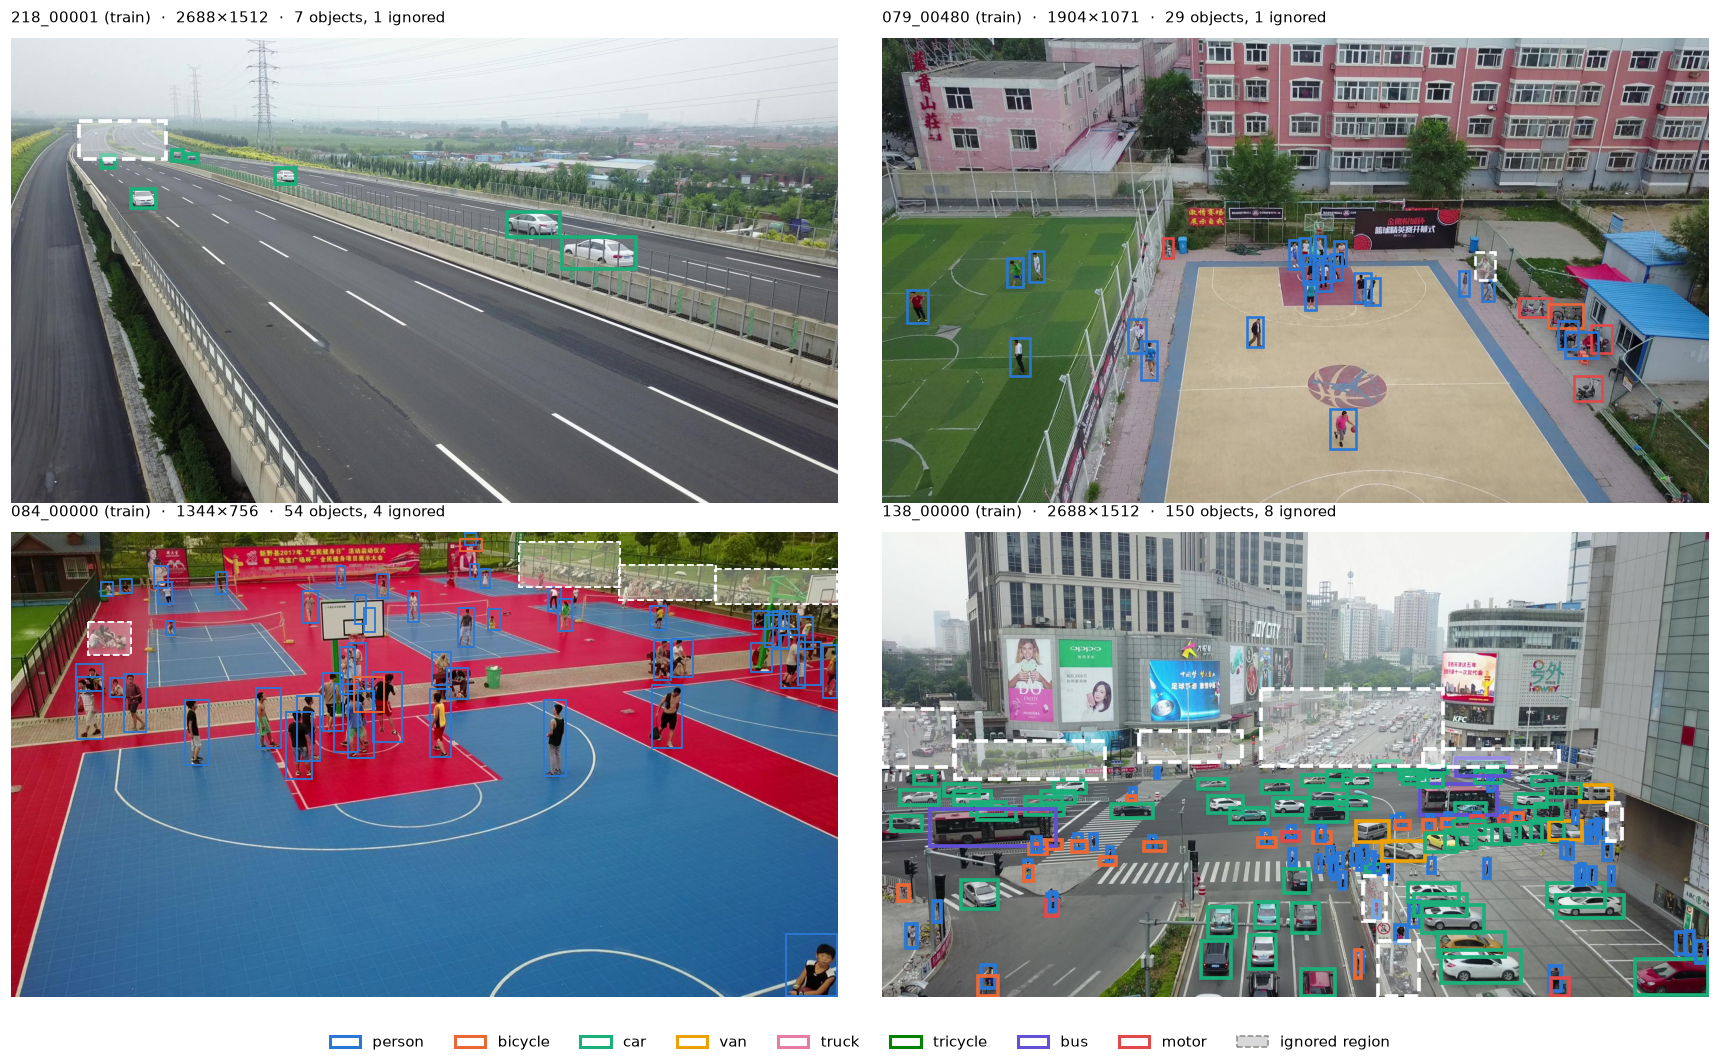

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9.6))
for ax, r in zip(axes.flat, sample.itertuples()):
    s = r.split
    ob, ig = OBJ[s][OBJ[s].coco_id == r.coco_id], IGN[s][IGN[s].coco_id == r.coco_id]
    ax.imshow(Image.open(P.data / r.file_name))
    lw = 1.2 * max(r.width, 1344) / 1344
    for b in ob.itertuples():
        ax.add_patch(Rectangle((b.x, b.y), b.w, b.h, fill=False, ec=COLORS[b.cls], lw=lw))
    for b in ig.itertuples():
        ax.add_patch(Rectangle((b.x, b.y), b.w, b.h, fc=(1, 1, 1, 0.35), ec="white", ls="--", lw=lw))
    ax.set_title(f"{short(r.clip)} ({s})  ·  {r.width}×{r.height}  ·  {len(ob)} objects, {len(ig)} ignored",
                 fontsize=10, fontweight="normal")
    ax.axis("off")
    # YOLO txt must give the same boxes as COCO: every COCO box has a YOLO box within 1 px
    cls, boxes, _ = load_gt(P.data, r.file_name, r.width, r.height)
    coco = ob[["x", "y", "w", "h"]].to_numpy()
    assert len(coco) == len(boxes), r.file_name
    if len(coco):
        assert np.abs(coco[:, None] - boxes[None]).max(-1).min(1).max() < 1.0, r.file_name
handles = [Patch(fill=False, ec=COLORS[i], lw=2, label=n) for i, n in enumerate(CLASS_NAMES)]
handles.append(Patch(fc=(0.85, 0.85, 0.85), ec=INK_3, ls="--", label="ignored region"))
fig.legend(handles=handles, loc="lower center", ncol=9, fontsize=10)
fig.tight_layout(rect=(0, 0.045, 1, 1), h_pad=1.5, w_pad=1)
save_fig(fig, "eda_samples", P)
print("COCO and YOLO labels agree on all sampled frames")